# Notebook 7 — Your project: from electrons to an infrared spectrum

**Project week.** Choose one triatomic molecule and carry out the full workflow you used for CO₂:

1. equilibrium geometry (B3LYP/def2-SVP),
2. harmonic normal modes and IR intensities,
3. a machine-learned surface and dipole model, tested on held-out data,
4. classical MD at 300 K (and one other temperature), with the 3-D movie,
5. the IR spectrum from MD, compared with the harmonic result and with experiment.

Finish with **an abstract (≤ 200 words) and one or two figures** (see the end of this notebook and the handout).

| molecule | atoms (outer–central–outer) | shape | experiment, cm⁻¹ (gas) | why it is interesting |
|---|---|---|---|---|
| N₂O | N–N–O | linear | ν₁ 1285, ν₂ 589, ν₃ 2224 | greenhouse gas; all modes IR-active, no inversion centre |
| OCS | O–C–S | linear | ν₁ 859, ν₂ 520, ν₃ 2062 | the most abundant sulfur gas in the atmosphere |
| HCN | H–C–N | linear | ν₁ 3311, ν₂ 712, ν₃ 2097 | a light atom: fast C–H stretch, needs a smaller time step |
| CS₂ | S–C–S | linear | ν₁ 658 (Raman), ν₂ 397, ν₃ 1535 | same symmetry as CO₂; heavier atoms |
| H₂O | H–O–H | bent | ν₁ 3657, ν₂ 1595, ν₃ 3756 | 3N − 6 = 3 modes, all IR-active; permanent dipole |
| SO₂ | O–S–O | bent | ν₁ 1151, ν₂ 518, ν₃ 1362 | volcanic gas; bent, symmetric |

Work through the sections in order. Most functions are generalisations of ones you already wrote: copy your code
from Notebooks 4–6 and adapt it. The changes needed are listed in each section.

In [1]:
import sys, time
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from pyscf import gto, dft
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
import labkit as lk

SYSTEMS = {   # symbols (outer, central, outer), starting r1, r2 (A), angle (deg), symmetric?, MD time step (fs)
    "N2O": dict(symbols=["N", "N", "O"], r1=1.13, r2=1.19, angle=180, symmetric=False, dt=0.5),
    "OCS": dict(symbols=["O", "C", "S"], r1=1.16, r2=1.56, angle=180, symmetric=False, dt=0.5),
    "HCN": dict(symbols=["H", "C", "N"], r1=1.07, r2=1.15, angle=180, symmetric=False, dt=0.25),
    "CS2": dict(symbols=["S", "C", "S"], r1=1.55, r2=1.55, angle=180, symmetric=True, dt=0.5),
    "H2O": dict(symbols=["H", "O", "H"], r1=0.96, r2=0.96, angle=104.5, symmetric=True, dt=0.25),
    "SO2": dict(symbols=["O", "S", "O"], r1=1.45, r2=1.45, angle=119, symmetric=True, dt=0.5),
}

import os
SYSTEM = os.environ.get("LAB_SYSTEM", "N2O")      # <-- choose your molecule, e.g. SYSTEM = "OCS"
cfg = SYSTEMS[SYSTEM]
symbols, symmetric = cfg["symbols"], cfg["symmetric"]
masses = np.array([lk.MASS[s] for s in symbols])
m3 = np.repeat(masses, 3)
LINEAR = cfg["angle"] == 180
print(SYSTEM, symbols, "linear" if LINEAR else "bent", "symmetric" if symmetric else "asymmetric")

N2O ['N', 'N', 'O'] linear asymmetric


## 1. Geometry
**Changes from Notebook 4:** the bonds need not be equal and the molecule may be bent, so a one-variable scan is not
enough. Use PySCF's analytic gradient, `mf.nuc_grad_method().kernel()` (hartree/bohr, shape (3, 3)), with
`scipy.optimize.minimize(..., jac=True, method="BFGS")` over the 9 Cartesian coordinates.

In [2]:
def build(r1, r2, angle_deg):
    """Outer atom 0 on -z, central atom at the origin, outer atom 2 in the xz plane."""
    a = np.radians(angle_deg)
    return np.array([[0, 0, -r1], [0, 0, 0], [r2 * np.sin(np.pi - a), 0, r2 * np.cos(np.pi - a)]])

def run_dft(X, basis="def2-svp", xc="b3lyp"):
    mol = gto.M(atom=[[s, tuple(x)] for s, x in zip(symbols, X)], basis=basis, verbose=0)
    mf = dft.RKS(mol); mf.xc = xc; mf.kernel()
    return mf

def energy_and_gradient(x):
    """Energy (eV) and gradient (eV/A) for flattened coordinates x."""
    mf = run_dft(x.reshape(3, 3))
    g = mf.nuc_grad_method().kernel() * lk.HARTREE_TO_EV / lk.BOHR_TO_ANG
    return mf.e_tot * lk.HARTREE_TO_EV, g.ravel()

t = time.time()
res = minimize(energy_and_gradient, build(cfg["r1"], cfg["r2"], cfg["angle"]).ravel(), jac=True, method="BFGS",
               options={"gtol": 1e-4})
X0 = res.x.reshape(3, 3)
E_min = res.fun
b1, b2 = X0[0] - X0[1], X0[2] - X0[1]
print(f"optimised in {time.time() - t:.0f} s ({res.nit} steps): r1 = {np.linalg.norm(b1):.4f} A, r2 = {np.linalg.norm(b2):.4f} A, "
      f"angle = {np.degrees(np.arccos(b1 @ b2 / np.linalg.norm(b1) / np.linalg.norm(b2))):.2f} deg")
lk.show_molecule(symbols, X0, labels=True)

optimised in 39 s (4 steps): r1 = 1.1302 A, r2 = 1.1817 A, angle = 180.00 deg


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 2. Harmonic analysis and IR intensities
**Changes from Notebook 4:** a bent molecule has 3N − 6 = 3 vibrations (6 near-zero eigenvalues), a linear one 3N − 5 = 4.
Select the vibrations as the eigenvalues above 100 cm⁻¹.

In [3]:
def dipole_dft(X):
    return run_dft(X).dip_moment(unit="Debye", verbose=0)

t = time.time()
mf0 = run_dft(X0)
H = mf0.Hessian().kernel().transpose(0, 2, 1, 3).reshape(9, 9) * lk.HARTREE_TO_EV / lk.BOHR_TO_ANG**2
lam, L = np.linalg.eigh(H / np.sqrt(np.outer(m3, m3)))
wn_all = lk.omega_to_wavenumber(np.sign(lam) * np.sqrt(np.abs(lam) * lk.ACC))
keep = wn_all > 100
wn, modes = wn_all[keep], L[:, keep]
disp = modes / np.sqrt(m3)[:, None]
A = []
for k in range(len(wn)):
    dX = (0.01 * disp[:, k]).reshape(3, 3)
    A.append(42.256 * np.sum(((dipole_dft(X0 + dX) - dipole_dft(X0 - dX)) / 0.02)**2))
A = np.array(A)
n_modes = len(wn)
print(f"({time.time() - t:.0f} s)  all eigenvalues (cm^-1): {np.round(wn_all, 0)}")
for k in range(n_modes):
    print(f"mode {k}: {wn[k]:7.1f} cm^-1   A = {A[k]:7.1f} km/mol")
print("dipole at equilibrium:", np.round(dipole_dft(X0), 3), "D")

(12 s)  all eigenvalues (cm^-1): [ -17.  -17.  -11.  -11.   19.  606.  606. 1380. 2418.]
mode 0:   605.9 cm^-1   A =    12.0 km/mol
mode 1:   605.9 cm^-1   A =    12.0 km/mol
mode 2:  1380.3 cm^-1   A =    50.1 km/mol
mode 3:  2418.2 cm^-1   A =   339.7 km/mol


dipole at equilibrium: [-0.     0.     0.006] D


In [4]:
for k in range(n_modes):
    print(f"mode {k}: {wn[k]:.0f} cm^-1")
    lk.animate_mode(symbols, X0, disp[:, k], amplitude=0.25)

mode 0: 606 cm^-1


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

mode 1: 606 cm^-1


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

mode 2: 1380 cm^-1


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

mode 3: 2418 cm^-1


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 3. Training data
**Changes from Notebook 5:** `n_modes` modes instead of 4. Compute your own training **and** test sets (there is no
precomputed data for these molecules). Budget: about 0.3–1 s per point. 200 training and 50 test points take 1–5 minutes.

In [5]:
omega = 2 * np.pi * lk.C_CM_PER_FS * wn
N_TRAIN, N_TEST, E_MAX = 200, 50, 0.6

def sample_geometry(rng, E_max=E_MAX):
    eps = E_max * rng.random() * rng.dirichlet(np.ones(n_modes))
    Q = np.sqrt(2 * eps * lk.ACC) / omega * rng.choice([-1, 1], n_modes)
    return X0 + ((modes @ Q) / np.sqrt(m3)).reshape(3, 3)

rng = np.random.default_rng(1)
t = time.time()
X_all = np.array([sample_geometry(rng) for _ in range(N_TRAIN + N_TEST)])
E_all, mu_all = [], []
for X in X_all:
    mf = run_dft(X)
    E_all.append(mf.e_tot * lk.HARTREE_TO_EV - E_min)
    mu_all.append(mf.dip_moment(unit="Debye", verbose=0))
E_all, mu_all = np.array(E_all), np.array(mu_all)
np.savez(f"{SYSTEM}_samples.npz", X=X_all, E=E_all, mu=mu_all, X0=X0)
print(f"{len(X_all)} points in {time.time() - t:.0f} s; saved {SYSTEM}_samples.npz")
X_tr, E_tr, mu_tr = X_all[:N_TRAIN], E_all[:N_TRAIN], mu_all[:N_TRAIN]
X_te, E_te, mu_te = X_all[N_TRAIN:], E_all[N_TRAIN:], mu_all[N_TRAIN:]

250 points in 170 s; saved N2O_samples.npz


## 4. The machine-learned surface and dipole
**Changes from Notebook 5:**
- Features are the same $(r_1, r_2, \cos\theta)$, with the central atom as atom 1.
- Add the swapped copies **only if the two outer atoms are identical** (`symmetric`).
- Dipole model: if the outer atoms differ, they need their own charge coefficients (8 instead of 4). Use
  $\boldsymbol\phi = (1,\ r_1 - r_{1e},\ r_2 - r_{2e},\ \cos\theta - \cos\theta_e)$.

In [6]:
def features(X):
    b1, b2 = X[..., 0, :] - X[..., 1, :], X[..., 2, :] - X[..., 1, :]
    r1, r2 = np.linalg.norm(b1, axis=-1), np.linalg.norm(b2, axis=-1)
    return np.stack([r1, r2, np.sum(b1 * b2, -1) / (r1 * r2)], -1)

F_tr, F_te = features(X_tr), features(X_te)
Fs = np.concatenate([F_tr, F_tr[:, [1, 0, 2]]]) if symmetric else F_tr
Es = np.concatenate([E_tr, E_tr]) if symmetric else E_tr
f_mean, f_scale = Fs.mean(0), Fs.std(0)
kernel = ConstantKernel(1.0, (1e-3, 1e7)) * RBF([1.0] * 3, (1e-2, 1e5)) + WhiteKernel(1e-5, (1e-6, 1e-2))
gp = GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=2).fit((Fs - f_mean) / f_scale, Es)

def energy(X):
    F = features(np.asarray(X)).reshape(-1, 3)
    return gp.predict((F - f_mean) / f_scale).reshape(np.shape(X)[:-2])

rms = np.sqrt(np.mean((energy(X_te) - E_te)**2)) * 1000
print(gp.kernel_)
print(f"energy test RMS = {rms:.3f} meV = {rms / 1000 * lk.EV_TO_CM1:.2f} cm^-1")

Fe = features(X0)
def phi(F, swap=False):
    F = F[..., [1, 0, 2]] if swap else F
    r1e, r2e = (Fe[1], Fe[0]) if swap else (Fe[0], Fe[1])
    return np.stack([np.ones(F.shape[:-1]), F[..., 0] - r1e, F[..., 1] - r2e, F[..., 2] - Fe[2]], -1)

def dipole_design(X):
    F = features(X)
    b1, b2 = X[..., 0, :] - X[..., 1, :], X[..., 2, :] - X[..., 1, :]
    A1 = phi(F)[..., None, :] * b1[..., :, None]
    A2 = phi(F, swap=True)[..., None, :] * b2[..., :, None]
    A = A1 + A2 if symmetric else np.concatenate([A1, A2], -1)
    return lk.DEBYE_PER_E_ANG * A

c_dip, *_ = np.linalg.lstsq(dipole_design(X_tr).reshape(-1, 4 if symmetric else 8), mu_tr.ravel(), rcond=None)

def dipole(X):
    return dipole_design(np.asarray(X)) @ c_dip

print(f"dipole test RMS = {np.sqrt(np.mean(np.sum((dipole(X_te) - mu_te)**2, -1))):.4f} D;  "
      f"RMS dipole {np.sqrt(np.mean(np.sum(mu_te**2, -1))):.3f} D")

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 21 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 30 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


312**2 * RBF(length_scale=[14, 12.4, 188]) + WhiteKernel(noise_level=1e-06)
energy test RMS = 0.038 meV = 0.31 cm^-1
dipole test RMS = 0.0203 D;  RMS dipole 0.352 D


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 22 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


GP   606.7  DFT   605.9  (+0.8 cm^-1)
GP   606.8  DFT   605.9  (+0.9 cm^-1)
GP  1380.0  DFT  1380.3  (-0.2 cm^-1)
GP  2419.0  DFT  2418.2  (+0.8 cm^-1)


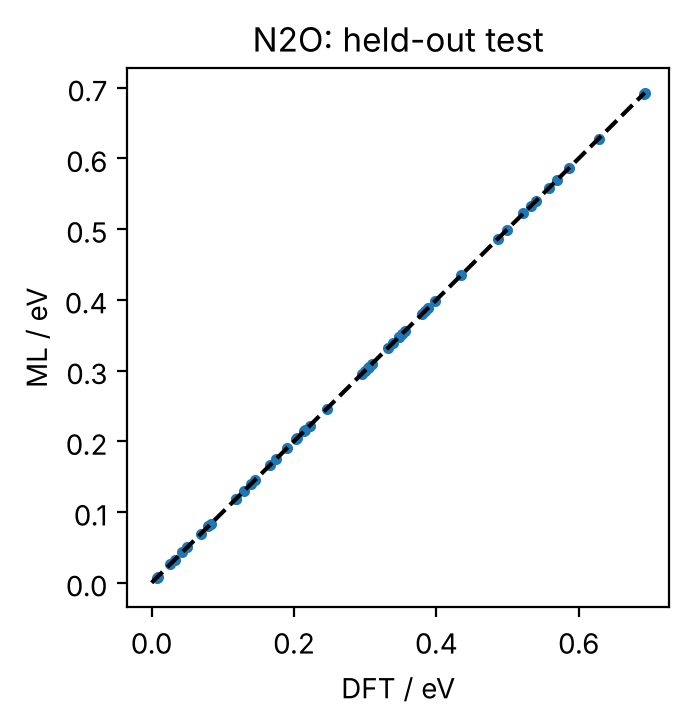

In [7]:
# parity plot and harmonic check (Figure candidates)
step, x0 = 0.002, X0.ravel()
Hgp = np.zeros((9, 9))
for i in range(9):
    for j in range(i, 9):
        P = []
        for si, sj in ((1, 1), (1, -1), (-1, 1), (-1, -1)):
            x = x0.copy(); x[i] += si * step; x[j] += sj * step; P.append(x.reshape(3, 3))
        e = energy(np.array(P)); Hgp[i, j] = Hgp[j, i] = (e[0] - e[1] - e[2] + e[3]) / (4 * step**2)
lam_gp = np.linalg.eigvalsh(Hgp / np.sqrt(np.outer(m3, m3)))
wn_gp = lk.omega_to_wavenumber(np.sqrt(np.abs(lam_gp) * lk.ACC))[-n_modes:]
for a, b in zip(wn_gp, wn):
    print(f"GP {a:7.1f}  DFT {b:7.1f}  ({a - b:+.1f} cm^-1)")
plt.figure(figsize=(3.5, 3.5)); plt.plot(E_te, energy(X_te), "."); plt.plot([0, E_te.max()], [0, E_te.max()], "k--")
plt.xlabel("DFT / eV"); plt.ylabel("ML / eV"); plt.title(f"{SYSTEM}: held-out test"); plt.show()

## 5. Molecular dynamics
**Changes from Notebook 6:** use `cfg["dt"]` (0.25 fs for molecules with H), `n_modes` modes in the thermal start, and the
new `energy` and `dipole` functions. Your `forces` and `run_md` should work unchanged.

In [8]:
masses_c = masses[:, None]

def forces(X, h=1e-3):
    P = np.repeat(X[None], 18, axis=0)
    for k in range(9):
        P[2 * k].flat[k] += h; P[2 * k + 1].flat[k] -= h
    e = energy(P)
    return -((e[0::2] - e[1::2]) / (2 * h)).reshape(3, 3)

def run_md(X, V, dt, n_steps, save_every=1):
    X, V = X.copy(), V.copy(); traj, mus, et = [], [], []
    F = forces(X)
    for step in range(n_steps):
        V += 0.5 * dt * F / masses_c * lk.ACC; X += dt * V
        F = forces(X); V += 0.5 * dt * F / masses_c * lk.ACC
        if step % save_every == 0:
            traj.append(X.copy()); mus.append(dipole(X))
            et.append(energy(X) + 0.5 * np.sum(masses_c * V**2) / lk.ACC)
    return np.array(traj), np.array(mus), np.array(et)

def thermal_start(T, rng):
    kT = lk.KB_EV * T
    Q = rng.normal(size=n_modes) * np.sqrt(kT * lk.ACC) / omega
    X = X0 + ((modes @ Q) / np.sqrt(m3)).reshape(3, 3)
    V = rng.normal(size=(3, 3)) * np.sqrt(kT * lk.ACC / masses_c)
    V -= (masses_c * V).sum(0) / masses_c.sum()
    return X, V

def ir_spectrum(mu, dt_fs):
    m = (mu - mu.mean(0)) * np.hanning(len(mu))[:, None]
    n = 4 * len(m)
    nu = np.fft.rfftfreq(n, d=dt_fs) / lk.C_CM_PER_FS
    return nu, np.sum(np.abs(np.fft.rfft(m, n=n, axis=0))**2, 1) * nu**2

dt = cfg["dt"]
X, V = thermal_start(300, np.random.default_rng(5))
t = time.time()
traj, mu, et = run_md(X, V, dt, int(2000 / dt), save_every=1)
print(f"2 ps in {time.time() - t:.0f} s; energy fluctuation {1000 * np.ptp(et):.2f} meV")
lk.animate_trajectory(symbols, traj, stride=max(1, int(1 / dt)), interval=30)

2 ps in 2 s; energy fluctuation 0.75 meV


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [9]:
def averaged_spectrum(T, n_traj=24, t_ps=4, seed=0):
    rng, acc = np.random.default_rng(seed), 0
    every = max(1, int(1 / dt))
    for _ in range(n_traj):
        X, V = thermal_start(T, rng)
        _, m, _ = run_md(X, V, dt, int(t_ps * 1000 / dt), save_every=every)
        nu, I = ir_spectrum(m, every * dt)
        acc = acc + I
    return nu, acc / n_traj

t = time.time()
spectra = {T: averaged_spectrum(T) for T in (300, 1000)}
print(f"({time.time() - t:.0f} s)")

(120 s)


## 6. Figures for your report
A good figure tells one story. Suggested Figure 1: MD spectra at two temperatures with the harmonic sticks and the
experimental fundamentals marked. Suggested Figure 2: the molecule and its normal modes, or a film strip of the trajectory,
or the ML parity plot. Label axes with units, and save as PNG at 300 dpi.

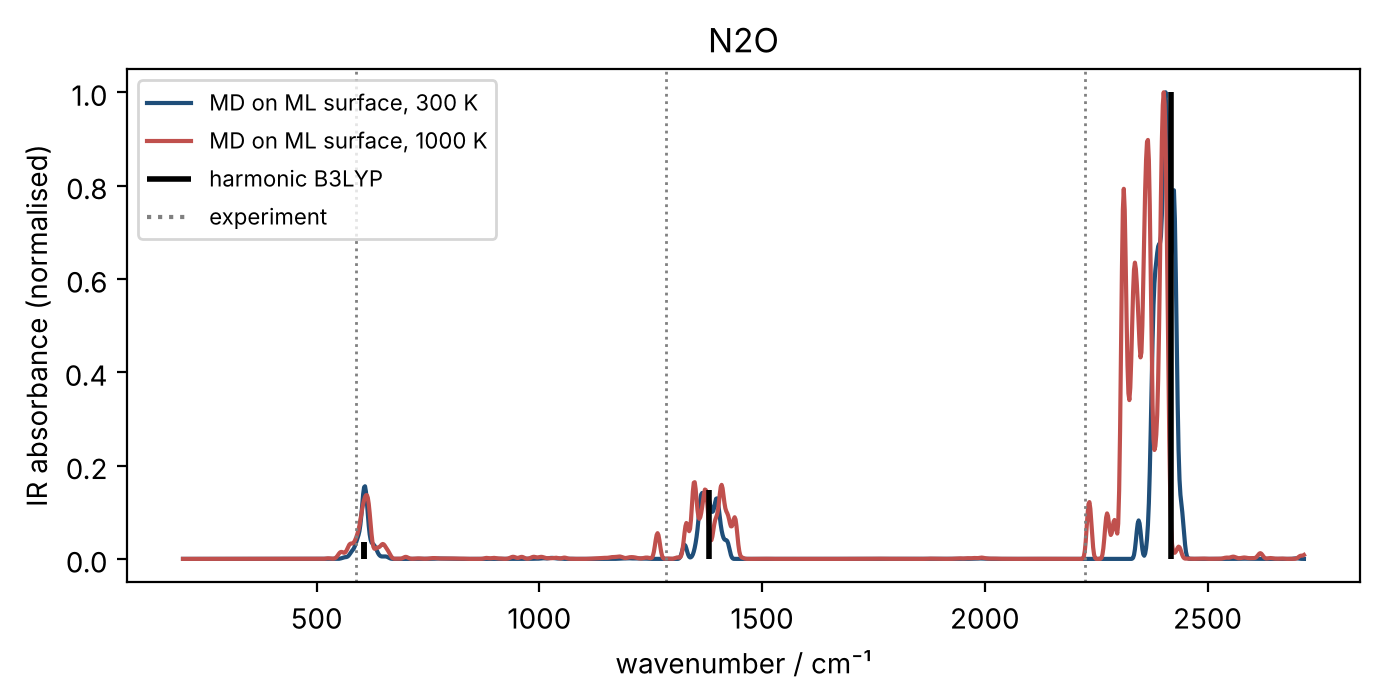

In [10]:
expt = {"N2O": (1285, 589, 2224), "OCS": (859, 520, 2062), "HCN": (3311, 712, 2097),
        "CS2": (658, 397, 1535), "H2O": (3657, 1595, 3756), "SO2": (1151, 518, 1362)}[SYSTEM]
fig, ax = plt.subplots(figsize=(7, 3.6))
top = max(wn.max(), max(expt)) + 300
for (T, (nu, I)), col in zip(spectra.items(), ("#1f4e79", "#c0504d")):
    w = (nu > 200) & (nu < top)
    ax.plot(nu[w], I[w] / I[w].max(), color=col, label=f"MD on ML surface, {T} K")
ax.vlines(wn, 0, A / A.max(), color="k", lw=2, label="harmonic B3LYP")
for e in expt:
    ax.axvline(e, color="0.5", ls=":", lw=1)
ax.plot([], [], color="0.5", ls=":", label="experiment")
ax.set_xlabel("wavenumber / cm⁻¹"); ax.set_ylabel("IR absorbance (normalised)"); ax.set_title(SYSTEM)
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{SYSTEM}_figure1.png", dpi=300); plt.show()

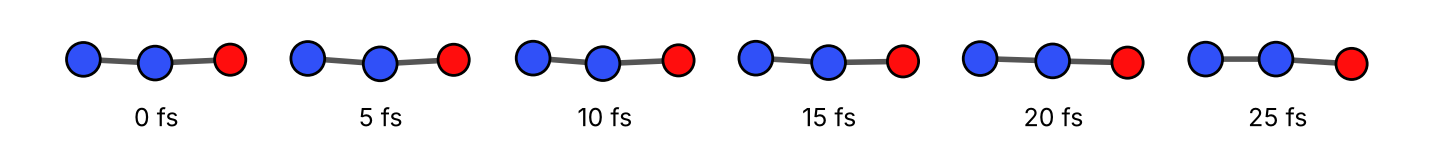

In [11]:
fig, ax = plt.subplots(figsize=(9, 1.8))
lk.trajectory_strip(symbols, traj, np.arange(len(traj)) * dt, frames=list(range(0, int(30 / dt), int(5 / dt))), ax=ax)
plt.savefig(f"{SYSTEM}_trajectory_strip.png", dpi=300, bbox_inches="tight"); plt.show()

## 7. Results table and abstract
Fill in the table, then write the abstract.

| mode | description | harmonic B3LYP / cm⁻¹ | IR intensity / km mol⁻¹ | MD 300 K peak / cm⁻¹ | experiment / cm⁻¹ |
|---|---|---|---|---|---|
| | | | | | |

**Abstract (≤ 200 words).** In one paragraph: the question; the methods (B3LYP/def2-SVP, harmonic analysis,
Gaussian-process surface with its test error, classical MD); the main quantitative results; and the physical explanation of
which vibrations absorb infrared light and why. A reader should understand what you found without your figures.

*Write your abstract here.*

<div style="background:#fff4e5;border-left:4px solid #e08a00;padding:8px 12px">

**Instructor notes**

Worked reference for N₂O is the executed output above. Things to look for in student work: (1) correct mode count (4 for linear, 3 for bent) and an explanation of why all modes of N₂O/OCS/HCN are IR-active (no inversion centre) while ν₁ of CS₂ is not; (2) a test-set error, not a training error; (3) a time step suited to the fastest mode (0.25 fs with H); (4) honest comparison: harmonic B3LYP overestimates stretches by a few per cent, and classical MD at 300 K gives near-harmonic band positions, not quantum fundamentals (no zero-point energy); (5) for molecules with a permanent dipole (N₂O, OCS, HCN, H₂O, SO₂) the MD spectrum has a pure-rotation band at low wavenumber, which students may notice and should be able to explain (the plot starts at 200 cm⁻¹). H₂O: the bend overtone and the near-degenerate stretches make a good discussion; SO₂ and CS₂ are the slowest (heavier atoms, more electrons).

</div>